# 02A · Trần Nhật Dương – Q1 & Q2
*Bối cảnh hành trình, khoảng cách/hướng đi (Q1) và thời hạn theo khung giờ trong ngày (Q2).*

- **Dữ liệu:** UCI #603 – *In-Vehicle Coupon Recommendation* (`12.684` kịch bản lái xe giả định, nhãn `Y` = ý định chấp nhận `0/1`).
- **Tiêu chí độ sâu đăng ký:** Q1 (**D3, D4, D5**) · Q2 (**D2, D4, D5**).
- **Quy ước chung:** `acceptance_rate = mean(Y) × 100 (%)`; báo cáo đầy đủ cỡ mẫu `n`, chênh lệch điểm phần trăm (`pp`), khoảng tin cậy bootstrap 95% (`n_boot=2.000`, `seed=42`), và chỉ kết luận **mối liên hệ trong khảo sát** (không suy diễn nhân quả).

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from coupon_project.config import FIGURES_DIR, RAW_CSV_PATH, TARGET
from coupon_project.data_io import load_raw_data, row_count_log
from coupon_project.journey import (
    EXPIRATION_ORDER,
    TIME_ORDER,
    TRAVEL_BAND_ORDER,
    add_time_band,
    check_flags,
    q1_direction_diff,
    q1_distance_diff,
    q2_expiry_diff,
    q2_pivots,
)
from coupon_project.metrics import group_summary
from coupon_project.plotting import plot_bars_ci, plot_heatmap, set_style
from coupon_project.quality import missing_table, target_is_binary

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
df = load_raw_data(RAW_CSV_PATH)
assert target_is_binary(df, TARGET), "Target Y phải là nhị phân 0/1 và không có NaN."

print(f"Raw dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Overall acceptance rate: {df[TARGET].mean() * 100:.2f}% ({df[TARGET].sum():,}/{len(df):,})")
print(f"Exact duplicate rows (trên đủ 26 cột): {df.duplicated().sum()}")

Raw dataset: 12,684 rows x 26 columns
Overall acceptance rate: 56.84% (7,210/12,684)
Exact duplicate rows (trên đủ 26 cột): 74


---
## Q1 · Khoảng cách và hướng đi có liên quan đến tỷ lệ chấp nhận sau khi xét mục đích chuyến đi & loại coupon?

- **Owner:** Trần Nhật Dương  
- **Biến sử dụng:** `toCoupon_GEQ5min`, `toCoupon_GEQ15min`, `toCoupon_GEQ25min`, `direction_same`, `direction_opp`, `destination`, `coupon`, `Y`  
- **Tiêu chí chứng minh:** **D3** (tạo `travel_time_band` có kiểm tra nhất quán cờ ngưỡng), **D4** (phân tầng theo `destination` và `coupon`), **D5** (ước lượng 95% bootstrap CI cho tỷ lệ và chênh lệch điểm %).

### Motivation & đối tượng hưởng lợi
- **Ai cần thông tin này?** Đội ngũ thiết kế hệ thống gợi ý ưu đãi trên xe / ứng dụng bản đồ dẫn đường (in-car infotainment, navigation apps) và các chuỗi cửa hàng muốn gửi voucher đúng bối cảnh di chuyển.
- **Quyết định được hỗ trợ:** Nên giới hạn bán kính thời gian di chuyển (`5–<15`, `15–<25`, `≥25` phút) và ưu tiên điểm cùng hướng đi (`direction_same`) ở mức nào cho từng loại hình dịch vụ và mục đích hành trình, tránh làm người lái phải đi vòng quá xa.
- **Giả thuyết ban đầu (cần kiểm chứng):** Thời gian di chuyển đến điểm dùng coupon càng dài hoặc phải rẽ ngược hướng có thể liên hệ với tỷ lệ chấp nhận thấp hơn, nhưng mức nhạy cảm sẽ khác nhau theo loại coupon và mục đích chuyến đi.

### Q1.1 · Kiểm tra chất lượng dữ liệu, tính nhất quán cờ khoảng cách & log số dòng

Trước khi biến đổi dữ liệu:
1. Kiểm tra missingness trên 8 cột liên quan đến Q1 (không áp dụng `dropna` toàn bảng một cách máy móc).
2. Kiểm tra tính nhất quán logic của 3 biến ngưỡng thời gian (`toCoupon_GEQ25min == 1` thì bắt buộc `toCoupon_GEQ15min == 1` và `toCoupon_GEQ5min == 1`) và hai biến hướng (`direction_same + direction_opp == 1`).
3. Ghi nhận số dòng trước/sau và kiểm tra độ nhạy với 74 dòng trùng lặp hoàn toàn trên 26 cột (vì dataset không có `participant_id`, các dòng trùng có thể đến từ nhiều người trả lời chọn giống nhau nên giữ nguyên tập gốc và đối chiếu độ nhạy).

In [2]:
q1_cols = [
    "toCoupon_GEQ5min",
    "toCoupon_GEQ15min",
    "toCoupon_GEQ25min",
    "direction_same",
    "direction_opp",
    "destination",
    "coupon",
    TARGET,
]
q1_raw = df[q1_cols].copy()
n_before_q1 = len(q1_raw)

print("Missing table (Q1 columns):")
display(missing_table(q1_raw))

flag_audit = check_flags(q1_raw)
print("Journey flag audit:", flag_audit)

print("\nPhân phối tổ hợp (toCoupon_GEQ5min, toCoupon_GEQ15min, toCoupon_GEQ25min):")
display(
    q1_raw.groupby(["toCoupon_GEQ5min", "toCoupon_GEQ15min", "toCoupon_GEQ25min"])
    .size()
    .rename("n")
    .to_frame()
)

print(row_count_log(n_before_q1, len(q1_raw), "Q1 subset (0 missing in Q1 columns, keep all rows)"))

Missing table (Q1 columns):


,missing_count,missing_pct
toCoupon_GEQ5min,0,0.0
toCoupon_GEQ15min,0,0.0
toCoupon_GEQ25min,0,0.0
direction_same,0,0.0
direction_opp,0,0.0
destination,0,0.0
coupon,0,0.0
Y,0,0.0


Journey flag audit: {'n_rows': 12684, 'geq5_always_one': True, 'invalid_geq_hierarchy_count': 0, 'direction_complement_ok': True}

Phân phối tổ hợp (toCoupon_GEQ5min, toCoupon_GEQ15min, toCoupon_GEQ25min):


n
toCoupon_GEQ5min toCoupon_GEQ15min toCoupon_GEQ25min      
1                0                 0                  5562
                 1                 0                  5611
                                   1                  1511

Q1 subset (0 missing in Q1 columns, keep all rows): 12,684 -> 12,684 rows (delta +0)


### Q1.2 · Phương pháp & triển khai D3, D4, D5

1. **D3 (`add_time_band`):** Vì `toCoupon_GEQ5min == 1` ở 100% quan sát (`12.684` dòng) và không có cờ vi phạm thứ tự ngưỡng (`invalid_geq_hierarchy_count = 0`), ta gộp 2 cờ `GEQ15min` và `GEQ25min` thành biến phân loại có thứ tự `travel_time_band`:
   - `5-<15 min` (`GEQ15=0, GEQ25=0`)
   - `15-<25 min` (`GEQ15=1, GEQ25=0`)
   - `>=25 min` (`GEQ15=1, GEQ25=1`)
   - *(Lưu ý ngữ nghĩa: đây là **ngưỡng thời gian ước tính**, không phải khoảng cách GPS chính xác.)*
2. **Mối liên hệ thô (chưa phân tầng):** Tính `n`, `accepted`, `rate_pct` và 95% bootstrap CI theo `travel_time_band`, `direction_same`, và giao điểm `travel_time_band × direction_same`.
3. **D4 (Phân tầng kiểm soát confounder):** Phân tích lại trong từng `destination` (`Home`, `Work`, `No Urgent Place`) và từng `coupon` (5 loại), đồng thời xét `destination × travel_time_band × direction_same` để nhận diện các ô rỗng cấu trúc và kiểm tra liệu xu hướng thô có bị đảo chiều (nghịch lý Simpson) hay không.
4. **D5 (Khoảng tin cậy chênh lệch):** Tính chênh lệch điểm % (`diff_pp`) và 95% bootstrap CI (`n_boot=2.000, seed=42`) cho cặp `5-<15 min` vs `>=25 min` và `direction_same = 1` vs `0`.

In [3]:
q1_df = add_time_band(q1_raw)
print(row_count_log(len(q1_raw), len(q1_df), "D3 add_time_band (no rows dropped)"))

print("\n--- 1. Mối liên hệ thô theo travel_time_band ---")
q1_band_summary = group_summary(q1_df, ["travel_time_band"])
display(q1_band_summary)

print("--- 2. Mối liên hệ thô theo direction_same ---")
q1_dir_summary = group_summary(q1_df, ["direction_same"])
display(q1_dir_summary)
display(q1_direction_diff(q1_df))

print("--- 3. Bảng giao điểm travel_time_band x direction_same ---")
q1_band_dir_summary = group_summary(q1_df, ["travel_time_band", "direction_same"])
display(q1_band_dir_summary)

D3 add_time_band (no rows dropped): 12,684 -> 12,684 rows (delta +0)

--- 1. Mối liên hệ thô theo travel_time_band ---


,travel_time_band,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_sample
0,5-<15 min,5562,3416,61.42,60.16,62.69,False
1,15-<25 min,5611,3146,56.07,54.77,57.33,False
2,>=25 min,1511,648,42.89,40.50,45.27,False


--- 2. Mối liên hệ thô theo direction_same ---


,direction_same,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_sample
0,0,9960,5624,56.47,55.53,57.46,False
1,1,2724,1586,58.22,56.42,60.10,False


,group_a,group_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_sample
0,same_direction (1),opposite_or_na (0),2724,9960,58.22,56.47,1.76,-0.3,3.72,False


--- 3. Bảng giao điểm travel_time_band x direction_same ---


,travel_time_band,direction_same,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_sample
0,5-<15 min,0,3583,2228,62.18,60.59,63.83,False
1,5-<15 min,1,1979,1188,60.03,57.86,62.20,False
2,15-<25 min,0,4866,2748,56.47,55.10,57.89,False
3,15-<25 min,1,745,398,53.42,49.66,56.91,False
4,>=25 min,0,1511,648,42.89,40.37,45.40,False


In [4]:
print("--- 4. D4: Phân tầng theo destination x travel_time_band ---")
q1_dest_band = group_summary(q1_df, ["destination", "travel_time_band"])
display(q1_dest_band)

print("--- 5. D5: Chênh lệch 5-<15 min vs >=25 min (tổng thể, theo destination, theo coupon) ---")
display(q1_distance_diff(q1_df))
display(q1_distance_diff(q1_df, by=["destination"]))
q1_coupon_dist_diff = q1_distance_diff(q1_df, by=["coupon"])
display(q1_coupon_dist_diff)

print("--- 6. D4 + D5: Ảnh hưởng direction_same sau khi phân tầng theo destination & travel_time_band ---")
display(q1_direction_diff(q1_df, by=["destination"]))
q1_dir_strat = q1_direction_diff(q1_df, by=["destination", "travel_time_band"])
display(q1_dir_strat)

print("--- 7. Kiểm tra độ nhạy với 74 dòng trùng lặp (full dataset drop_duplicates) ---")
df_dedup = add_time_band(df.drop_duplicates())
print(row_count_log(len(df), len(df_dedup), "Sensitivity check: drop exact duplicates"))
display(q1_distance_diff(df_dedup))
display(q1_direction_diff(df_dedup, by=["destination"]))

--- 4. D4: Phân tầng theo destination x travel_time_band ---


,destination,travel_time_band,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_sample
0,Home,5-<15 min,1792,990,55.25,52.84,57.59,False
1,Home,15-<25 min,973,464,47.69,44.60,50.87,False
2,Home,>=25 min,472,185,39.19,34.75,43.86,False
3,No Urgent Place,5-<15 min,2639,1694,64.19,62.41,66.01,False
4,No Urgent Place,15-<25 min,3644,2288,62.79,61.14,64.30,False
5,Work,5-<15 min,1131,732,64.72,61.89,67.64,False
6,Work,15-<25 min,994,394,39.64,36.62,42.66,False
7,Work,>=25 min,1039,463,44.56,41.58,47.55,False


--- 5. D5: Chênh lệch 5-<15 min vs >=25 min (tổng thể, theo destination, theo coupon) ---


,group_a,group_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_sample
0,5-<15 min,>=25 min,5562,1511,61.42,42.89,18.53,15.64,21.27,False


,destination,group_a,group_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_sample
0,Home,5-<15 min,>=25 min,1792,472,55.25,39.19,16.05,10.98,21.11,False
1,No Urgent Place,5-<15 min,>=25 min,2639,0,64.19,NaN,NaN,NaN,NaN,True
2,Work,5-<15 min,>=25 min,1131,1039,64.72,44.56,20.16,15.99,24.20,False


,coupon,group_a,group_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_sample
0,Bar,5-<15 min,>=25 min,679,510,44.04,38.63,5.41,-0.13,11.10,False
1,Carry out & Take away,5-<15 min,>=25 min,873,265,75.26,73.21,2.05,-3.89,8.38,False
2,Coffee House,5-<15 min,>=25 min,1923,310,54.81,34.52,20.29,14.74,26.00,False
3,Restaurant(20-50),5-<15 min,>=25 min,547,116,44.97,42.24,2.73,-7.04,11.98,False
4,Restaurant(<20),5-<15 min,>=25 min,1540,310,75.32,32.58,42.74,37.06,48.68,False


... (2 outputs left out)

,destination,travel_time_band,group_a,group_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_sample
0,Home,5-<15 min,same_direction (1),opposite_or_na (0),1179,613,58.69,48.61,10.08,5.19,14.90,False
1,Home,15-<25 min,same_direction (1),opposite_or_na (0),345,628,63.77,38.85,24.91,18.36,31.23,False
2,Home,>=25 min,same_direction (1),opposite_or_na (0),0,472,NaN,39.19,NaN,NaN,NaN,True
3,No Urgent Place,5-<15 min,same_direction (1),opposite_or_na (0),0,2639,NaN,64.19,NaN,NaN,NaN,True
4,No Urgent Place,15-<25 min,same_direction (1),opposite_or_na (0),0,3644,NaN,62.79,NaN,NaN,NaN,True
5,Work,5-<15 min,same_direction (1),opposite_or_na (0),800,331,62.00,71.30,-9.30,-14.79,-3.18,False
6,Work,15-<25 min,same_direction (1),opposite_or_na (0),400,594,44.50,36.36,8.14,2.11,14.23,False
7,Work,>=25 min,same_direction (1),opposite_or_na (0),0,1039,NaN,44.56,NaN,NaN,NaN,True


--- 7. Kiểm tra độ nhạy với 74 dòng trùng lặp (full dataset drop_duplicates) ---
Sensitivity check: drop exact duplicates: 12,684 -> 12,610 rows (delta -74)


,group_a,group_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_sample
0,5-<15 min,>=25 min,5551,1463,61.38,41.97,19.41,16.57,22.13,False


,destination,group_a,group_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_sample
0,Home,same_direction (1),opposite_or_na (0),1520,1710,59.80,42.46,17.35,13.95,20.58,False
1,No Urgent Place,same_direction (1),opposite_or_na (0),0,6266,NaN,63.34,NaN,NaN,NaN,True
2,Work,same_direction (1),opposite_or_na (0),1198,1916,56.09,45.98,10.11,6.50,13.78,False


### Q1.3 · Trực quan hóa (3 biểu đồ)

1. **Hình 1:** Heatmap `travel_time_band × direction_same` (thể hiện tỷ lệ chấp nhận `%`, số quan sát `n`, và làm rõ ô rỗng cấu trúc `>=25 min & direction_same = 1`).
2. **Hình 2:** Grouped bar chart theo `coupon × travel_time_band` kèm 95% bootstrap CI để thấy mức độ nhạy cảm với khoảng cách khác nhau rất mạnh giữa các loại coupon.
3. **Hình 3:** Biểu đồ phân tầng `destination × travel_time_band × direction_same` (D4 + D5) giải thích vì sao chênh lệch hướng đi thô chỉ `+1.76 pp` nhưng bên trong `Home` và `Work` lại chênh rất rõ (và đảo dấu ở `Work` `5-<15 min`).

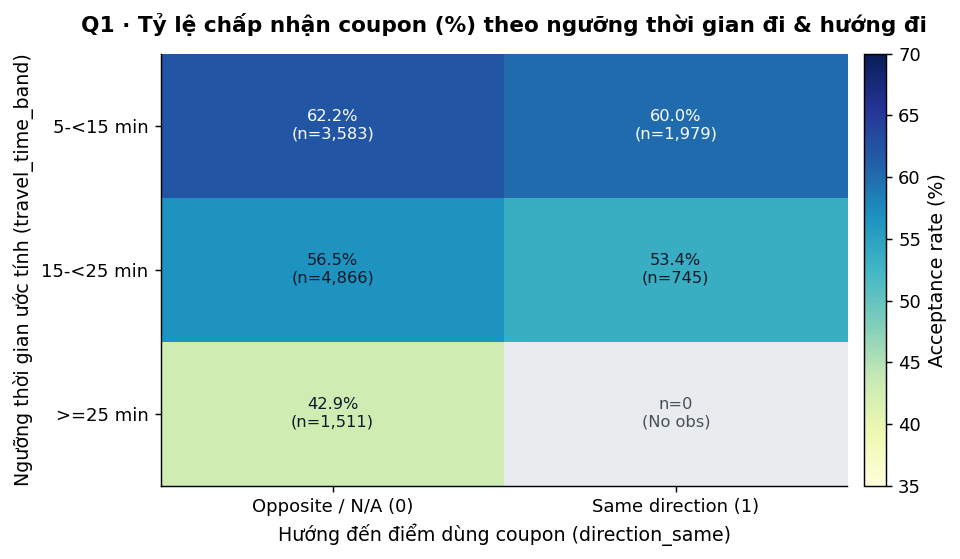

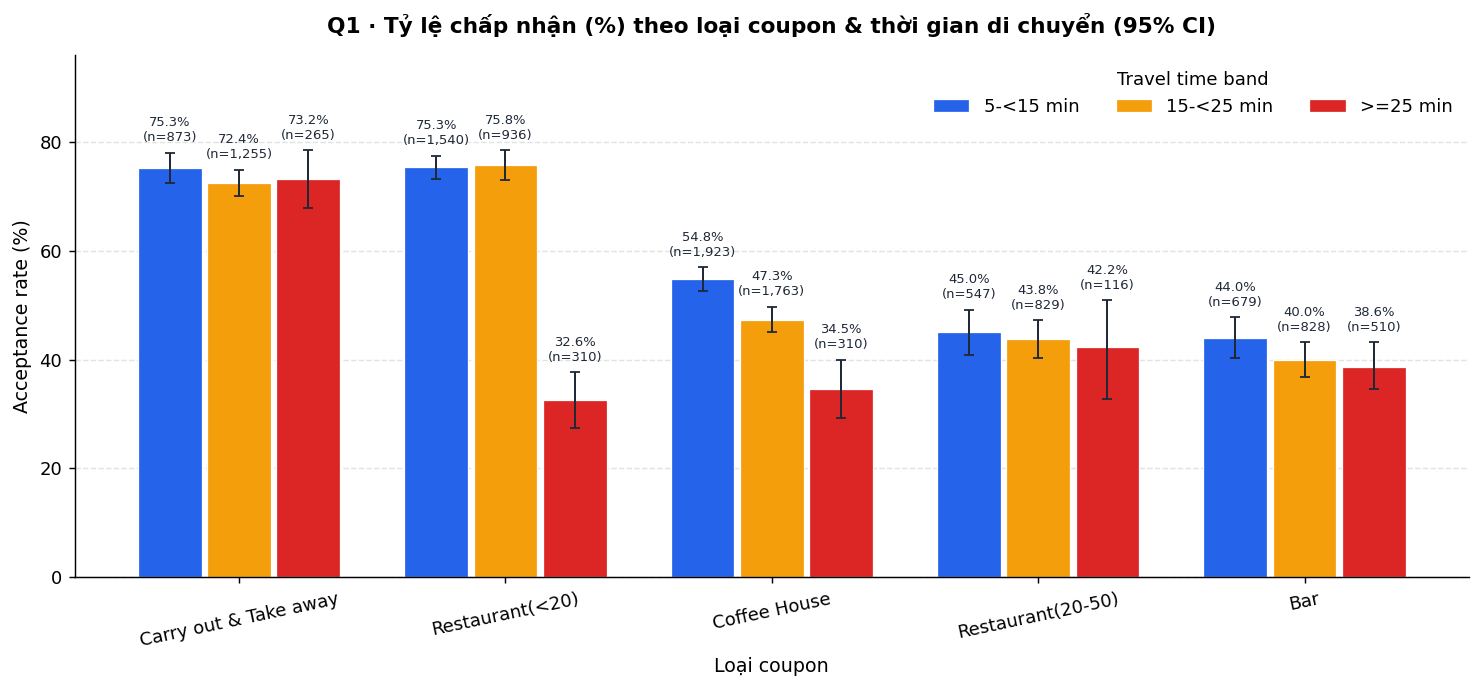

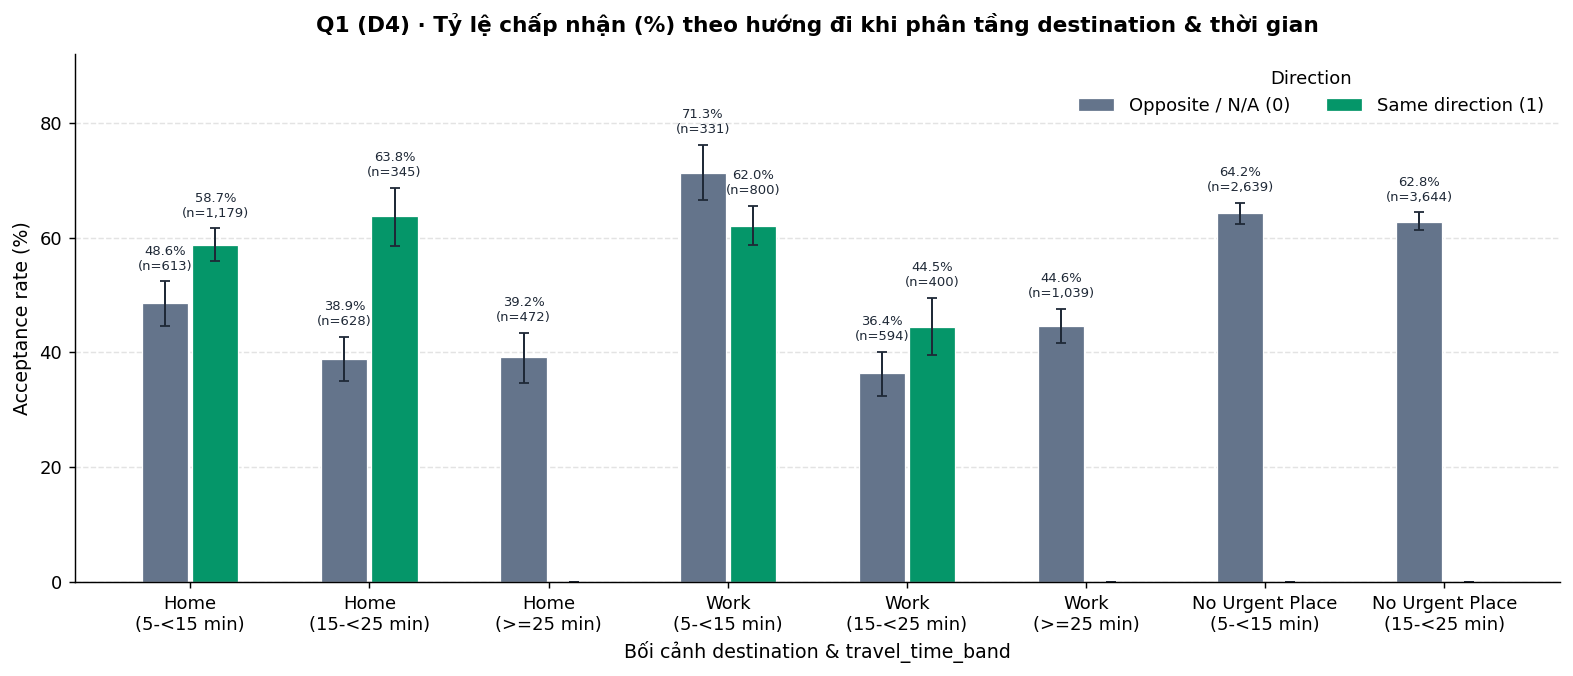

In [5]:
q1_hm_rate = (
    q1_df.pivot_table(
        index="travel_time_band",
        columns="direction_same",
        values=TARGET,
        aggfunc="mean",
        observed=False,
    )
    * 100.0
)
q1_hm_count = (
    q1_df.pivot_table(
        index="travel_time_band",
        columns="direction_same",
        values=TARGET,
        aggfunc="count",
        observed=False,
    )
    .fillna(0)
    .astype(int)
)
col_labels = {0: "Opposite / N/A (0)", 1: "Same direction (1)"}
q1_hm_rate = q1_hm_rate.rename(columns=col_labels)
q1_hm_count = q1_hm_count.rename(columns=col_labels)

fig1 = plot_heatmap(
    rate_matrix=q1_hm_rate,
    count_matrix=q1_hm_count,
    title="Q1 · Tỷ lệ chấp nhận coupon (%) theo ngưỡng thời gian đi & hướng đi",
    xlabel="Hướng đến điểm dùng coupon (direction_same)",
    ylabel="Ngưỡng thời gian ước tính (travel_time_band)",
    cbar_label="Acceptance rate (%)",
    out_path=FIGURES_DIR / "q1_fig1_heatmap_travel_time_direction.png",
    vmin=35,
    vmax=70,
    figsize=(7.8, 4.4),
)
plt.show()

q1_coupon_summary = group_summary(q1_df, ["coupon", "travel_time_band"])
coupon_order = [
    "Carry out & Take away",
    "Restaurant(<20)",
    "Coffee House",
    "Restaurant(20-50)",
    "Bar",
]
fig2 = plot_bars_ci(
    summary_df=q1_coupon_summary,
    x_col="coupon",
    hue_col="travel_time_band",
    x_order=coupon_order,
    hue_order=TRAVEL_BAND_ORDER,
    title="Q1 · Tỷ lệ chấp nhận (%) theo loại coupon & thời gian di chuyển (95% CI)",
    xlabel="Loại coupon",
    ylabel="Acceptance rate (%)",
    out_path=FIGURES_DIR / "q1_fig2_grouped_bar_coupon_travel_time.png",
    colors=["#2563EB", "#F59E0B", "#DC2626"],
    figsize=(11.5, 5.4),
    ylim=(0, 96),
    rotate_xticks=12,
    legend_title="Travel time band",
)
plt.show()

q1_dest_dir_summary = group_summary(
    q1_df, ["destination", "travel_time_band", "direction_same"]
)
q1_dest_dir_summary["stratum"] = (
    q1_dest_dir_summary["destination"].astype(str)
    + "\n("
    + q1_dest_dir_summary["travel_time_band"].astype(str)
    + ")"
)
q1_dest_dir_summary["direction_label"] = q1_dest_dir_summary["direction_same"].map(
    {0: "Opposite / N/A (0)", 1: "Same direction (1)"}
)
stratum_order = [
    "Home\n(5-<15 min)",
    "Home\n(15-<25 min)",
    "Home\n(>=25 min)",
    "Work\n(5-<15 min)",
    "Work\n(15-<25 min)",
    "Work\n(>=25 min)",
    "No Urgent Place\n(5-<15 min)",
    "No Urgent Place\n(15-<25 min)",
]
fig3 = plot_bars_ci(
    summary_df=q1_dest_dir_summary,
    x_col="stratum",
    hue_col="direction_label",
    x_order=stratum_order,
    hue_order=["Opposite / N/A (0)", "Same direction (1)"],
    title="Q1 (D4) · Tỷ lệ chấp nhận (%) theo hướng đi khi phân tầng destination & thời gian",
    xlabel="Bối cảnh destination & travel_time_band",
    ylabel="Acceptance rate (%)",
    out_path=FIGURES_DIR / "q1_fig3_stratified_destination_direction.png",
    colors=["#64748B", "#059669"],
    figsize=(12.2, 5.3),
    ylim=(0, 92),
    legend_title="Direction",
)
plt.show()

### Q1.4 · Trả lời câu hỏi nghiên cứu Q1 bằng số liệu thực & Giới hạn

1. **Nhóm thời gian nào có tỷ lệ chấp nhận cao nhất?**  
   - Trên toàn mẫu (`n = 12.684`), nhóm gần nhất **`5–<15 min`** đạt tỷ lệ chấp nhận cao nhất là **`61.42%`** (`3.416 / 5.562`, 95% CI `[60.16%, 62.69%]`), theo sau là `15–<25 min` đạt `56.07%` (`3.146 / 5.611`, 95% CI `[54.77%, 57.33%]`), và thấp nhất là `>=25 min` chỉ đạt **`42.89%`** (`648 / 1.511`, 95% CI `[40.50%, 45.27%]`).
2. **Chênh lệch giữa gần và xa là bao nhiêu điểm phần trăm (95% CI)?**  
   - Giữa `5–<15 min` và `>=25 min`, mức chênh lệch là **`+18.53 điểm %`** (95% CI **`[+15.64, +21.27]` điểm %**). Kết quả giữ cùng chiều và tăng nhẹ khi kiểm tra độ nhạy loại 74 dòng trùng lặp (`12.610` dòng: `+19.41 pp`, 95% CI `[+16.57, +22.13] pp`).
3. **Xu hướng có giữ nguyên khi phân tầng theo `destination` và `coupon` (D4)?**  
   - **Theo `destination`:** Ở `Home`, `5–<15 min` (`55.25%`, `n=1.792`) cao hơn `>=25 min` (`39.19%`, `n=472`) là **`+16.05 pp`** (95% CI `[+10.98, +21.11] pp`). Ở `Work`, `5–<15 min` (`64.72%`, `n=1.131`) cao hơn `>=25 min` (`44.56%`, `n=1.039`) là **`+20.16 pp`** (95% CI `[+15.99, +24.20] pp`). Riêng `No Urgent Place` **không có bất kỳ quan sát nào ở `>=25 min`** (`n=0`, ô rỗng cấu trúc theo thiết kế khảo sát), nhưng chênh lệch `5–<15 min` (`64.19%`, `n=2.639`) vs `15–<25 min` (`62.79%`, `n=3.644`) nhỏ hơn nhiều (`+1.40 pp`).
   - **Theo `coupon`:** Khoảng cách liên hệ **không đồng đều giữa các loại coupon**! Giảm mạnh nhất ở **`Restaurant(<20)`** (`75.32%` ở `5–<15 min` giảm xuống `32.58%` ở `>=25 min`, chênh **`+42.74 pp`**, 95% CI `[+37.06, +48.68] pp`) và **`Coffee House`** (`54.81%` vs `34.52%`, chênh **`+20.29 pp`**, 95% CI `[+14.74, +26.00] pp`). Ngược lại, **`Carry out & Take away`** giữ mức cao ở cả 3 dải (`75.26%`, `72.43%`, `73.21%`; chênh gần–xa chỉ `+2.05 pp`, 95% CI `[-3.89, +8.38] pp`), tương tự `Bar` (`+5.41 pp`, CI `[-0.13, +11.10]`) và `Restaurant(20-50)` (`+2.73 pp`, CI `[-7.04, +11.98]`).
4. **Hướng đi cùng chiều (`direction_same`) có làm thay đổi mối liên hệ quan sát được không?**  
   - **Có — đây là ví dụ rõ của biến nhiễu `destination`:** Nếu nhìn thô trên toàn mẫu, `direction_same = 1` (`58.22%`, `n=2.724`) chỉ nhỉnh hơn `direction_same = 0` (`56.47%`, `n=9.960`) là `+1.76 pp` (95% CI `[-0.30, +3.72] pp` — không khác biệt rõ). Lý do là toàn bộ `6.283` quan sát `No Urgent Place` (có tỷ lệ nhận cao `63.38%`) đều mang nhãn `direction_same = 0`, kéo trung bình nhóm `0` lên.
   - Khi phân tầng đúng trong các chuyến đi có đích cố định: ở **`Home`**, đi cùng hướng làm tăng mạnh tỷ lệ nhận thêm **`+17.40 pp`** (95% CI `[+13.92, +20.84] pp`), đặc biệt ở dải `15–<25 min` lên tới **`+24.91 pp`** (`63.77%` vs `38.85%`, CI `[+18.36, +31.23]`). Ở **`Work`**, tổng thể cùng hướng cao hơn `+9.58 pp` (`[+6.00, +12.95]`), nhưng tại dải gần `5–<15 min` lại xuất hiện nghịch chiều: `direction_same = 0` (`71.30%`, `n=331`) cao hơn `direction_same = 1` (`62.00%`, `n=800`) tới `-9.30 pp` (`[-14.79, -3.18] pp`) — một tín hiệu đáng chú ý gắn với bối cảnh đi làm buổi sáng.
- **Điểm bất ngờ & ý nghĩa thực tế:** Coupon đồ ăn mang đi (`Carry out & Take away`) hầu như không giảm sức hút ngay cả khi cách `>=25 min` (`73.21%`), trong khi nhà hàng bình dân (`Restaurant(<20)`) sụt hơn `42 điểm %` khi xa `>=25 min`. Hệ thống gợi ý không nên áp dụng một ngưỡng bán kính cứng cho mọi loại ưu đãi: nên siết chặt bán kính (`<25 min`) và ưu tiên cùng chiều cho `Restaurant(<20)` hoặc `Coffee House` khi tài xế đang về nhà (`Home`), còn `Carry out` có thể mở rộng phạm vi hơn.
- **Hạn chế:** (1) `travel_time_band` chỉ là cờ ngưỡng rời rạc, không có phút hoặc km GPS thật; (2) tồn tại ô rỗng cấu trúc theo thiết kế kịch bản (`>=25 min` và `No Urgent Place` không có `direction_same=1`); (3) thiếu `participant_id` nên các kịch bản của cùng người khảo sát chưa tách độc lập hoàn toàn khi bootstrap; (4) dữ liệu phản ánh ý định giả định trong khảo sát, không khẳng định nhân quả.

---
## Q2 · Thời hạn coupon `2h` và `1d` có liên hệ thế nào với tỷ lệ chấp nhận theo thời điểm trong ngày và loại coupon?

- **Owner:** Trần Nhật Dương  
- **Biến sử dụng:** `expiration`, `time`, `coupon`, `destination`, `Y`  
- **Tiêu chí chứng minh:** **D2** (`pivot_table` và `melt` theo `time × expiration`), **D4** (kiểm soát loại `coupon` và cấu trúc ghép `time × destination`), **D5** (ước lượng 95% bootstrap CI cho chênh lệch `1d − 2h`).

### Motivation & đối tượng hưởng lợi
- **Ai cần thông tin này?** Bộ phận vận hành chiến dịch ưu đãi / quản lý chiến lược flash-offer trên nền tảng gợi ý địa điểm.
- **Quyết định được hỗ trợ:** Nên chọn thời hạn ngắn (`2h` — tạo cảm giác khẩn cấp, phù hợp nhu cầu tức thời) hay thời hạn dài hơn (`1d` — linh hoạt kế hoạch) ở từng khung giờ trong ngày và từng loại coupon.
- **Giả thuyết ban đầu (cần kiểm chứng):** `1d` nhìn chung hấp dẫn hơn nhờ tính linh hoạt, nhưng ở một số khung giờ hoặc loại hình cụ thể (như đi bar buổi tối), `2h` có thể không thua kém hoặc thậm chí cao hơn.

### Q2.1 · Kiểm tra dữ liệu, phân phối `expiration × time` và cấu trúc ghép `time × destination`

> **Lưu ý quan trọng:** Cột `time` chỉ gồm **5 khung giờ trong ngày** (`7AM`, `10AM`, `2PM`, `6PM`, `10PM`), **không phải** dữ liệu chuỗi thời gian qua nhiều ngày. Ngoài ra cần kiểm tra xem phân bố `1d` / `2h` có cân bằng qua từng khung giờ và loại coupon hay không.

In [6]:
q2_cols = ["expiration", "time", "coupon", "destination", TARGET]
q2_df = df[q2_cols].copy()
n_before_q2 = len(q2_df)

print("Missing table (Q2 columns):")
display(missing_table(q2_df))

print("Phân phối expiration:")
display(group_summary(q2_df, ["expiration"]))

print("Phân phối time:")
display(q2_df["time"].value_counts().reindex(TIME_ORDER).to_frame("n"))

print("Bảng chéo cấu trúc time x destination (giải thích confounder thiết kế khảo sát):")
display(pd.crosstab(q2_df["time"], q2_df["destination"]).reindex(TIME_ORDER))

print(row_count_log(n_before_q2, len(q2_df), "Q2 subset (0 missing in Q2 columns, keep all rows)"))

Missing table (Q2 columns):


,missing_count,missing_pct
expiration,0,0.0
time,0,0.0
coupon,0,0.0
destination,0,0.0
Y,0,0.0


Phân phối expiration:


,expiration,n,accepted,rate_pct,ci_low_pct,ci_high_pct,small_sample
0,1d,7091,4436,62.56,61.44,63.67,False
1,2h,5593,2774,49.60,48.22,50.96,False


Phân phối time:


,n
time,
7AM,3164
10AM,2275
2PM,2009
6PM,3230
10PM,2006


Bảng chéo cấu trúc time x destination (giải thích confounder thiết kế khảo sát):


destination,Home,No Urgent Place,Work
time,,,
7AM,0,0,3164
10AM,0,2275,0
2PM,0,2009,0
6PM,2123,1107,0
10PM,1114,892,0


Q2 subset (0 missing in Q2 columns, keep all rows): 12,684 -> 12,684 rows (delta +0)


### Q2.2 · Phương pháp & triển khai D2, D4, D5

1. **D2 (`pivot_table` & `melt`):** Tạo `pivot_table` tỷ lệ chấp nhận (`mean(Y) × 100`) và số lượng quan sát (`count`) theo `time × expiration`, tính cột chênh lệch `1d − 2h` (điểm %), đồng thời xuất dạng dài (`melt`) phục vụ so sánh và vẽ biểu đồ.
2. **D4 (Kiểm soát `coupon` & xét giao điểm `time × coupon`):** Vì tỷ trọng các loại `coupon` khác nhau giữa nhóm `1d` và `2h` tại từng khung giờ (đặc biệt tại `10AM`), cần so sánh `1d` vs `2h` **trong cùng từng loại coupon** và trong từng ô `time × coupon`, ghi nhận rõ các ô rỗng (`n = 0`) hoặc cỡ mẫu nhỏ.
3. **D5 (95% bootstrap CI):** Tính khoảng tin cậy bootstrap 95% (`n_boot=2.000, seed=42`) cho chênh lệch `1d − 2h` ở mức tổng thể, theo từng `time`, theo từng `coupon`, từng `destination` và toàn bộ 25 ô `time × coupon`.

In [7]:
q2_rate_pivot, q2_count_pivot, q2_long = q2_pivots(q2_df, index_cols=["time"])
print("--- 1. D2: Pivot table acceptance rate (%) theo time x expiration ---")
display(q2_rate_pivot)

print("--- 2. D2: Pivot table số lượng quan sát (n) theo time x expiration ---")
display(q2_count_pivot)

print("--- 3. D2: Bảng dạng dài (melt) time x expiration ---")
display(q2_long)

print("--- 4. D5: Chênh lệch 1d - 2h (pp, 95% CI) tổng thể và theo từng khung giờ ---")
display(q2_expiry_diff(q2_df))
q2_time_diffs = q2_expiry_diff(q2_df, by=["time"])
display(q2_time_diffs)

--- 1. D2: Pivot table acceptance rate (%) theo time x expiration ---


expiration,2h,1d,diff_1d_minus_2h_pp
time,,,
7AM,37.51,58.29,20.78
10AM,61.76,59.75,-2.01
2PM,55.85,71.77,15.92
6PM,54.53,61.82,7.29
10PM,36.90,63.03,26.13


--- 2. D2: Pivot table số lượng quan sát (n) theo time x expiration ---


expiration,2h,1d
time,,
7AM,1229,1935
10AM,1229,1046
2PM,709,1300
6PM,1491,1739
10PM,935,1071


--- 3. D2: Bảng dạng dài (melt) time x expiration ---


,time,expiration,rate_pct,n
0,7AM,2h,37.51,1229
1,10AM,2h,61.76,1229
2,2PM,2h,55.85,709
3,6PM,2h,54.53,1491
4,10PM,2h,36.90,935
5,7AM,1d,58.29,1935
6,10AM,1d,59.75,1046
7,2PM,1d,71.77,1300
8,6PM,1d,61.82,1739
9,10PM,1d,63.03,1071


--- 4. D5: Chênh lệch 1d - 2h (pp, 95% CI) tổng thể và theo từng khung giờ ---


,group_a,group_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_sample
0,1d,2h,7091,5593,62.56,49.6,12.96,11.21,14.63,False


,time,group_a,group_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_sample
0,7AM,1d,2h,1935,1229,58.29,37.51,20.78,17.42,24.18,False
1,10AM,1d,2h,1046,1229,59.75,61.76,-2.01,-5.82,1.96,False
2,2PM,1d,2h,1300,709,71.77,55.85,15.92,11.54,20.21,False
3,6PM,1d,2h,1739,1491,61.82,54.53,7.29,3.82,10.79,False
4,10PM,1d,2h,1071,935,63.03,36.90,26.13,21.81,30.24,False


In [8]:
print("--- 5. D4 + D5: Chênh lệch 1d - 2h theo loại coupon ---")
q2_coupon_diffs = q2_expiry_diff(q2_df, by=["coupon"])
display(q2_coupon_diffs)

print("--- 6. D4 + D5: Chênh lệch 1d - 2h theo destination ---")
display(q2_expiry_diff(q2_df, by=["destination"]))

print("--- 7. D4 + D5: Toàn bộ 25 giao điểm time x coupon (lưu ý ô rỗng & mẫu khiêm tốn) ---")
q2_tc_diffs = q2_expiry_diff(q2_df, by=["time", "coupon"])
display(q2_tc_diffs)

print("--- 8. Giải thích nghịch lý tại 10AM: cơ cấu tỷ trọng loại coupon (%) trong 1d vs 2h ---")
mix_10am = pd.crosstab(
    q2_df.loc[q2_df["time"] == "10AM", "coupon"],
    q2_df.loc[q2_df["time"] == "10AM", "expiration"],
    normalize="columns",
).mul(100).round(1)
display(mix_10am[["2h", "1d"]])

--- 5. D4 + D5: Chênh lệch 1d - 2h theo loại coupon ---


,coupon,group_a,group_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_sample
0,Bar,1d,2h,1556,461,41.20,40.35,0.85,-4.13,5.88,False
1,Carry out & Take away,1d,2h,1456,937,78.16,66.38,11.78,8.25,15.44,False
2,Coffee House,1d,2h,1769,2227,58.39,43.20,15.20,12.07,18.19,False
3,Restaurant(20-50),1d,2h,956,536,52.09,29.85,22.24,17.37,27.21,False
4,Restaurant(<20),1d,2h,1354,1432,83.16,58.94,24.22,20.92,27.45,False


--- 6. D4 + D5: Chênh lệch 1d - 2h theo destination ---


,destination,group_a,group_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_sample
0,Home,1d,2h,1830,1407,58.52,40.37,18.16,15.01,21.55,False
1,No Urgent Place,1d,2h,3326,2957,67.26,59.01,8.25,5.84,10.59,False
2,Work,1d,2h,1935,1229,58.29,37.51,20.78,17.30,24.22,False


--- 7. D4 + D5: Toàn bộ 25 giao điểm time x coupon (lưu ý ô rỗng & mẫu khiêm tốn) ---


,time,coupon,group_a,group_b,n_a,n_b,rate_a_pct,rate_b_pct,diff_pp,ci_low_pp,ci_high_pp,small_sample
0,7AM,Bar,1d,2h,487,0,36.55,NaN,NaN,NaN,NaN,True
1,7AM,Carry out & Take away,1d,2h,492,270,71.14,55.19,15.95,9.13,23.28,False
2,7AM,Coffee House,1d,2h,322,591,60.56,35.87,24.69,18.23,30.62,False
3,7AM,Restaurant(20-50),1d,2h,291,138,49.14,20.29,28.85,20.07,37.25,False
4,7AM,Restaurant(<20),1d,2h,343,230,76.38,31.30,45.08,37.81,52.50,False
5,10AM,Bar,1d,2h,378,66,39.68,16.67,23.02,12.72,32.90,False
6,10AM,Carry out & Take away,1d,2h,149,368,79.19,66.58,12.62,4.66,20.29,False
7,10AM,Coffee House,1d,2h,337,562,65.58,63.17,2.41,-3.88,8.88,False
8,10AM,Restaurant(20-50),1d,2h,70,42,68.57,50.00,18.57,0.46,36.67,False
9,10AM,Restaurant(<20),1d,2h,112,191,78.57,66.49,12.08,1.79,21.63,False


--- 8. Giải thích nghịch lý tại 10AM: cơ cấu tỷ trọng loại coupon (%) trong 1d vs 2h ---


expiration,2h,1d
coupon,,
Bar,5.4,36.1
Carry out & Take away,29.9,14.2
Coffee House,45.7,32.2
Restaurant(20-50),3.4,6.7
Restaurant(<20),15.5,10.7


### Q2.3 · Trực quan hóa (3 biểu đồ)

1. **Hình 1:** Grouped bar chart tỷ lệ chấp nhận (%) theo `time × expiration` (`2h` vs `1d`) kèm 95% bootstrap CI và số mẫu `n`.
2. **Hình 2:** Heatmap chênh lệch `1d − 2h` (điểm %) theo `coupon × time`, hiển thị rõ ô thiếu dữ liệu `2h` (`Bar` lúc `7AM` và `2PM`) và các ô có `n` khiêm tốn.
3. **Hình 3:** Forest plot chênh lệch `1d − 2h` (95% CI) theo từng loại `coupon` (trái) và riêng tại **`10AM`** theo từng `coupon` (phải) — minh họa trực diện nghịch lý Simpson ở khung `10AM`.

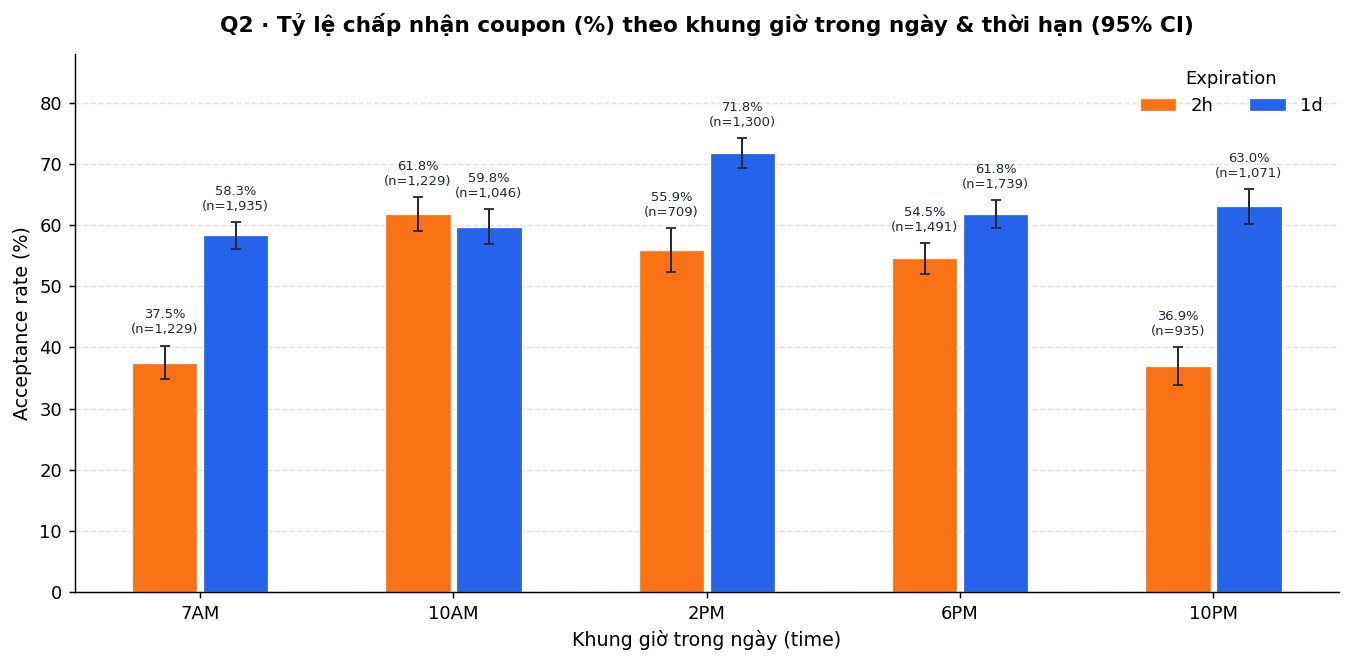

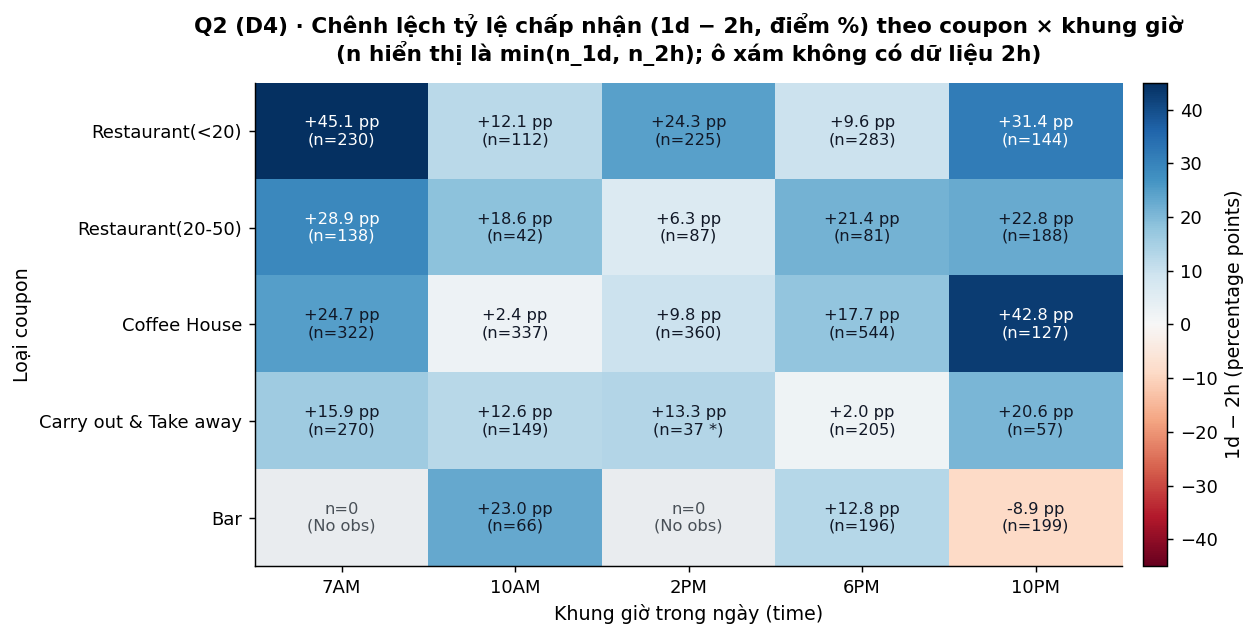

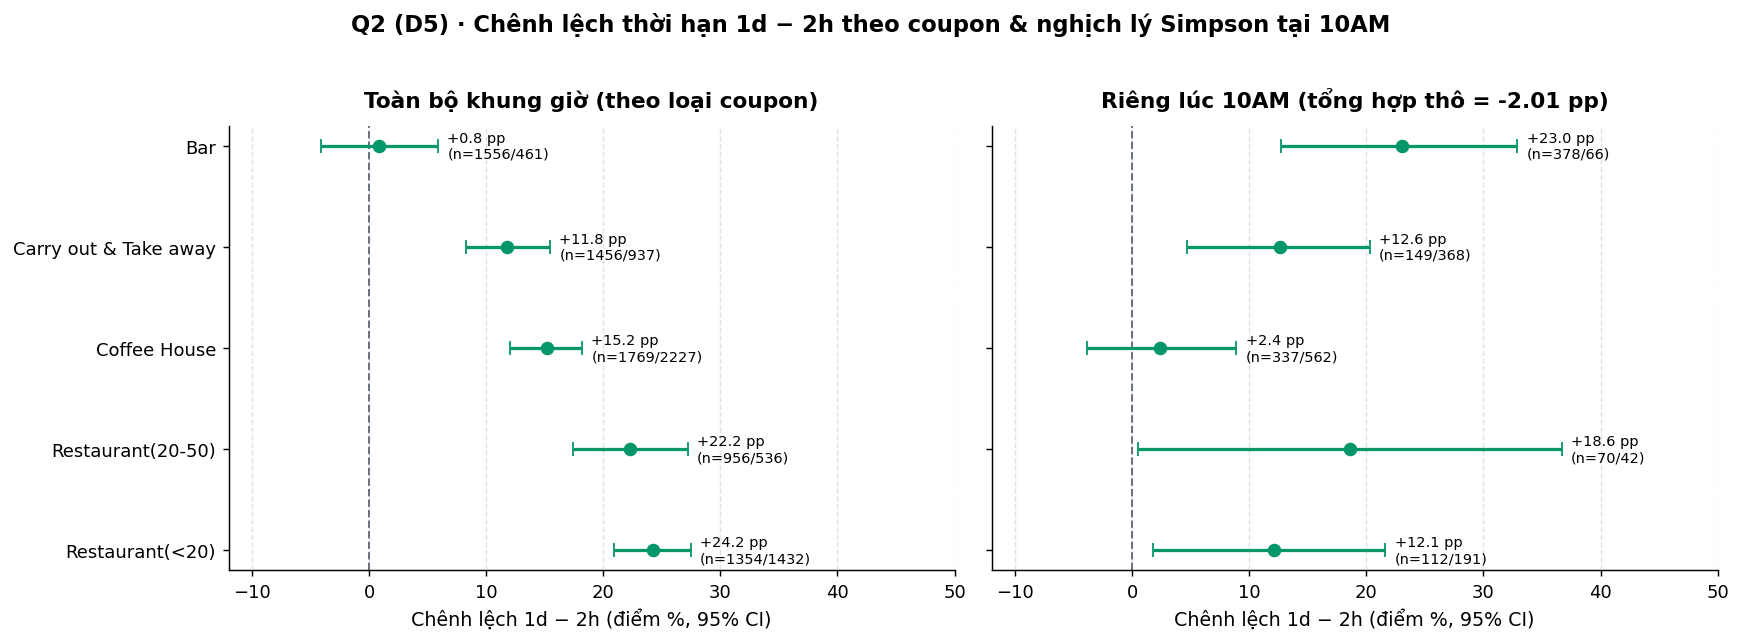

In [9]:
q2_time_exp_summary = group_summary(q2_df, ["time", "expiration"])
fig_q2_1 = plot_bars_ci(
    summary_df=q2_time_exp_summary,
    x_col="time",
    hue_col="expiration",
    x_order=TIME_ORDER,
    hue_order=EXPIRATION_ORDER,
    title="Q2 · Tỷ lệ chấp nhận coupon (%) theo khung giờ trong ngày & thời hạn (95% CI)",
    xlabel="Khung giờ trong ngày (time)",
    ylabel="Acceptance rate (%)",
    out_path=FIGURES_DIR / "q2_fig1_grouped_bar_time_expiration.png",
    colors=["#F97316", "#2563EB"],
    figsize=(10.5, 5.2),
    ylim=(0, 88),
    legend_title="Expiration",
)
plt.show()

coupon_order_q2 = [
    "Restaurant(<20)",
    "Restaurant(20-50)",
    "Coffee House",
    "Carry out & Take away",
    "Bar",
]
q2_tc_plot = q2_tc_diffs.copy()
q2_tc_plot["min_n"] = q2_tc_plot[["n_a", "n_b"]].min(axis=1)
diff_mat = q2_tc_plot.pivot(index="coupon", columns="time", values="diff_pp").reindex(
    index=coupon_order_q2, columns=TIME_ORDER
)
min_n_mat = (
    q2_tc_plot.pivot(index="coupon", columns="time", values="min_n")
    .reindex(index=coupon_order_q2, columns=TIME_ORDER)
    .fillna(0)
    .astype(int)
)
fig_q2_2 = plot_heatmap(
    rate_matrix=diff_mat,
    count_matrix=min_n_mat,
    title="Q2 (D4) · Chênh lệch tỷ lệ chấp nhận (1d − 2h, điểm %) theo coupon × khung giờ\n(n hiển thị là min(n_1d, n_2h); ô xám không có dữ liệu 2h)",
    xlabel="Khung giờ trong ngày (time)",
    ylabel="Loại coupon",
    cbar_label="1d − 2h (percentage points)",
    out_path=FIGURES_DIR / "q2_fig2_heatmap_diff_time_coupon.png",
    cmap="RdBu",
    vmin=-45,
    vmax=45,
    value_suffix=" pp",
    signed=True,
    min_n_warn=40,
    figsize=(10.2, 5.0),
)
plt.show()

set_style()
fig_q2_3, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), sharey=True)
panels = [
    (axes[0], q2_coupon_diffs.set_index("coupon").reindex(coupon_order_q2).reset_index(), "Toàn bộ khung giờ (theo loại coupon)"),
    (axes[1], q2_tc_diffs[q2_tc_diffs["time"] == "10AM"].set_index("coupon").reindex(coupon_order_q2).reset_index(), "Riêng lúc 10AM (tổng hợp thô = -2.01 pp)"),
]
for ax, pdf, subtitle in panels:
    ax.axvline(0.0, color="#6B7280", linestyle="--", linewidth=1.1)
    y_pos = np.arange(len(pdf))
    diffs = pdf["diff_pp"].to_numpy(dtype=float)
    lo = np.maximum(0.0, diffs - pdf["ci_low_pp"].to_numpy(dtype=float))
    hi = np.maximum(0.0, pdf["ci_high_pp"].to_numpy(dtype=float) - diffs)
    for i, (y, d, l_err, h_err) in enumerate(zip(y_pos, diffs, lo, hi)):
        col = "#059669" if d >= 0 else "#DC2626"
        ax.errorbar(d, y, xerr=[[l_err], [h_err]], fmt="o", color=col, ecolor=col, elinewidth=1.8, capsize=4, markersize=6.5)
        ax.text(d + h_err + 0.8, y, f"{d:+.1f} pp\n(n={int(pdf.loc[i, 'n_a'])}/{int(pdf.loc[i, 'n_b'])})", va="center", fontsize=8.0)
    ax.set_yticks(y_pos, labels=pdf["coupon"])
    ax.invert_yaxis()
    ax.set_xlim(-12, 50)
    ax.set_xlabel("Chênh lệch 1d − 2h (điểm %, 95% CI)")
    ax.set_title(subtitle, pad=10)
    ax.grid(axis="x", linestyle="--", alpha=0.35)
    ax.set_axisbelow(True)

fig_q2_3.suptitle("Q2 (D5) · Chênh lệch thời hạn 1d − 2h theo coupon & nghịch lý Simpson tại 10AM", fontsize=12.5, fontweight="bold", y=1.02)
fig_q2_3.tight_layout()
fig_q2_3.savefig(FIGURES_DIR / "q2_fig3_coupon_expiration_ci.png", bbox_inches="tight")
plt.show()

### Q2.4 · Trả lời câu hỏi nghiên cứu Q2 bằng số liệu thực & Giới hạn

1. **Tổng thể, loại thời hạn nào có tỷ lệ chấp nhận cao hơn và chênh bao nhiêu điểm %?**  
   - Trong toàn mẫu (`n = 12.684`), coupon thời hạn **`1d`** (`n = 7.091`) có tỷ lệ chấp nhận **`62.56%`**, cao hơn đáng kể so với **`2h`** (`n = 5.593`, **`49.60%`**). Mức chênh lệch tổng thể là **`+12.96 điểm %`** (95% bootstrap CI **`[+11.21, +14.63]` điểm %**).
2. **Xu hướng này có xảy ra ở cả 5 thời điểm trong ngày không?**  
   - Ở **4/5 khung giờ**, `1d` vượt trội rõ rệt so với `2h`: **`10PM`** chênh **`+26.13 pp`** (`63.03%` vs `36.90%`, CI `[+21.81, +30.24]`), **`7AM`** chênh **`+20.78 pp`** (`58.29%` vs `37.51%`, CI `[+17.42, +24.18]`), **`2PM`** chênh **`+15.92 pp`** (`71.77%` vs `55.85%`, CI `[+11.54, +20.21]`), và **`6PM`** chênh **`+7.29 pp`** (`61.82%` vs `54.53%`, CI `[+3.82, +10.79]`).
   - Riêng tại **`10AM`**, nếu nhìn bảng gộp thô thì `2h` (`61.76%`, `n=1.229`) lại hơi cao hơn `1d` (`59.75%`, `n=1.046`) với chênh **`-2.01 pp`** (CI `[-5.82, +1.96] pp`).
3. **Khi xét riêng từng loại coupon (D4), kết luận còn giống nhau không?**  
   - **Lý giải nghịch lý tại `10AM` (Simpson's paradox):** Khi tách riêng từng loại coupon ở `10AM`, **cả 5/5 loại coupon đều có `1d` cao hơn `2h`**: `Bar` (`+23.02 pp`, CI `[+12.72, +32.90]`), `Restaurant(20-50)` (`+18.57 pp`, CI `[+0.46, +36.67]`), `Carry out & Take away` (`+12.62 pp`, CI `[+4.66, +20.29]`), `Restaurant(<20)` (`+12.08 pp`, CI `[+1.79, +21.63]`) và `Coffee House` (`+2.41 pp`, CI `[-3.88, +8.88]`). Nguyên nhân bảng gộp `10AM` bị đảo dấu là do **mất cân bằng cơ cấu coupon**: nhóm `1d` lúc `10AM` có tới `36.1%` là `Bar` (vốn có tỷ lệ nhận thấp ~`39.7%`), trong khi nhóm `2h` lúc `10AM` chỉ có `5.4%` `Bar` mà tập trung nhiều vào `Coffee House` (`45.7%`) và `Carry out` (`29.9%`).
   - **Sự khác biệt theo loại coupon:** Mức chênh `1d − 2h` lớn nhất ở `Restaurant(<20)` (`+24.22 pp`, CI `[+20.92, +27.45]`) và `Restaurant(20-50)` (`+22.24 pp`, CI `[+17.37, +27.21]`), tiếp đến `Coffee House` (`+15.20 pp`) và `Carry out & Take away` (`+11.78 pp`). Ngược lại, **`Bar`** gần như không chênh ở mức tổng thể (`+0.85 pp`, CI `[-4.13, +5.88]`), và thậm chí tại **`10PM`**, coupon `Bar` `2h` (`50.25%`, `n=199`) lại cao hơn `1d` (`41.38%`, `n=203`) là `-8.87 pp` (CI `[-18.28, +1.11] pp`) — phù hợp trực giác rằng ưu đãi bar ban đêm gắn với nhu cầu đi ngay trong 2 giờ.
4. **Có nhóm nào không đủ dữ liệu để kết luận chắc chắn không?**  
   - **Có 2 ô rỗng hoàn toàn (`n_2h = 0`):** Coupon `Bar` ở **`7AM`** (`n_1d=487, n_2h=0`) và **`2PM`** (`n_1d=118, n_2h=0`) không có bất kỳ kịch bản `2h` nào nên không thể tính chênh lệch `1d − 2h`.
   - **Một số ô có cỡ mẫu nhỏ/khiêm tốn và CI rất rộng:** Ví dụ `Carry out & Take away` lúc `2PM` (`n_2h = 37`, CI `[-1.40, +28.39] pp`), `Restaurant(20-50)` lúc `10AM` (`n_2h = 42`, CI `[+0.46, +36.67] pp`), và `Carry out` lúc `10PM` (`n_2h = 57`, CI `[+8.49, +33.64] pp`).
- **Ý nghĩa thực tế & giới hạn:** Nhìn chung thời hạn `1d` vượt trội rõ ở các bối cảnh ăn uống (`Restaurant(<20)`, `Restaurant(20-50)`) và buổi sáng sớm `7AM` (đi làm) / tối muộn `10PM` (khi người lái khó ghé ngay trong 2 giờ). Chỉ riêng `Coffee House` lúc `10AM` (`63.17%` vs `65.58%`) hay `Carry out` lúc `6PM` (`81.46%` vs `83.48%`) và `Bar` lúc `10PM` (`50.25%` vs `41.38%`) cho thấy ưu đãi `2h` vẫn cạnh tranh tốt khi trùng đúng nhu cầu tức thời. **Hạn chế:** `time` chỉ là 5 mốc giờ trong ngày (không có dữ liệu nhiều ngày để phân tích xu hướng thời gian thực), `time` gắn chặt với `destination` (`7AM` = 100% `Work`, `10AM`/`2PM` = 100% `No Urgent Place`), phân bố `1d`/`2h` không cân bằng giữa các loại coupon, và khảo sát không cho phép kết luận nhân quả.